## Customer Segmentation Analysis Using K-Means
**Dataset: Customer Personality Analysis (marketing_campaign.csv)**

Assessment Submission: Checkpoint Challenge 2

## Chapter 1: Preparing the Data
# Step 1: Import Libraries

In [8]:
# Import necessary libraries for data manipulation, numerical operations, and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Set the visual style for all plots
sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")

Libraries imported successfully!


# Step 2: Load Dataset

In [10]:
import pandas as pd
import os

file_path = r'C:\Users\Hajir\MOVIE ANALYSIS GG\check2\marketing_campaign.csv'

customer_data = pd.read_csv(file_path, sep='\t')

print(f"Dataset successfully loaded with shape: {customer_data.shape}")
display(customer_data.head())

Dataset successfully loaded with shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


# Step 3: Data Inspection & Summary

In [11]:
# Print the first 5 rows of the dataframe
print("\n--- First 5 Rows of the Dataset ---")
customer_data.head()


--- First 5 Rows of the Dataset ---


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [12]:
# Get a concise summary of the dataframe, including data types and non-null values
print("\n--- Dataset Information ---")
customer_data.info()


--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsP

In [13]:
# Check for any missing (null) values in each column
print("\n--- Missing Values Check ---")
missing_values = customer_data.isnull().sum()
print(missing_values[missing_values > 0])


--- Missing Values Check ---
Income    24
dtype: int64


# Step 4: Data Cleaning & Preprocessing

In [14]:
# Drop rows with missing values (e.g., in Income column) to prevent clustering errors
customer_data_clean = customer_data.dropna().copy()
print(f"Rows before cleaning: {len(customer_data)}, Rows after cleaning: {len(customer_data_clean)}")

Rows before cleaning: 2240, Rows after cleaning: 2216


In [15]:
# Generate descriptive statistics for numerical columns
print("\n--- Descriptive Statistics ---")
customer_data_clean.describe()


--- Descriptive Statistics ---


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,...,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.000000,2216.0,2216.0,2216.000000
mean,5588.353339,1968.820397,52247.251354,0.441787,0.505415,49.012635,305.091606,26.356047,166.995939,37.637635,...,5.319043,0.073556,0.074007,0.073105,0.064079,0.013538,0.009477,3.0,11.0,0.150271
std,3249.376275,11.985554,25173.076661,0.536896,0.544181,28.948352,337.327920,39.793917,224.283273,54.752082,...,2.425359,0.261106,0.261842,0.260367,0.244950,0.115588,0.096907,0.0,0.0,0.357417
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2814.750000,1959.000000,35303.000000,0.000000,0.000000,24.000000,24.000000,2.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,174.500000,8.000000,68.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8421.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,505.000000,33.000000,232.250000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


# Step 5: Data Visualization - Feature Distributions

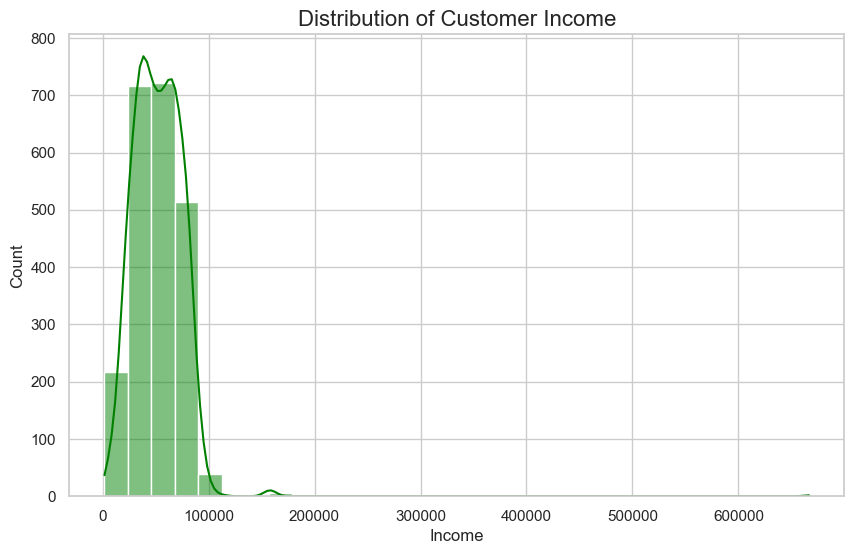

In [16]:
# Plot 1: Distribution of Customer Income
plt.figure(figsize=(10, 6))
sns.histplot(customer_data_clean['Income'], bins=30, kde=True, color='green')
plt.title('Distribution of Customer Income', fontsize=16)
plt.xlabel('Income', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

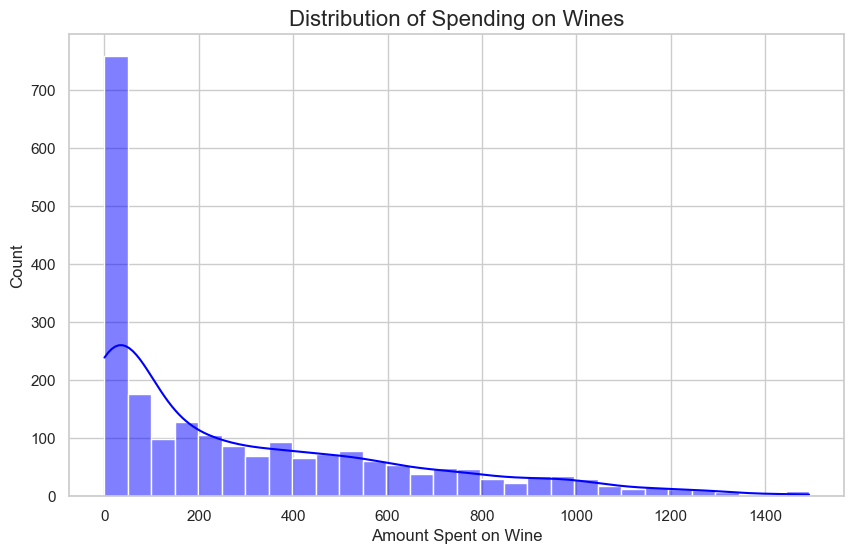

In [17]:
# Plot 2: Distribution of Spending on Wines
plt.figure(figsize=(10, 6))
sns.histplot(customer_data_clean['MntWines'], bins=30, kde=True, color='blue')
plt.title('Distribution of Spending on Wines', fontsize=16)
plt.xlabel('Amount Spent on Wine', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

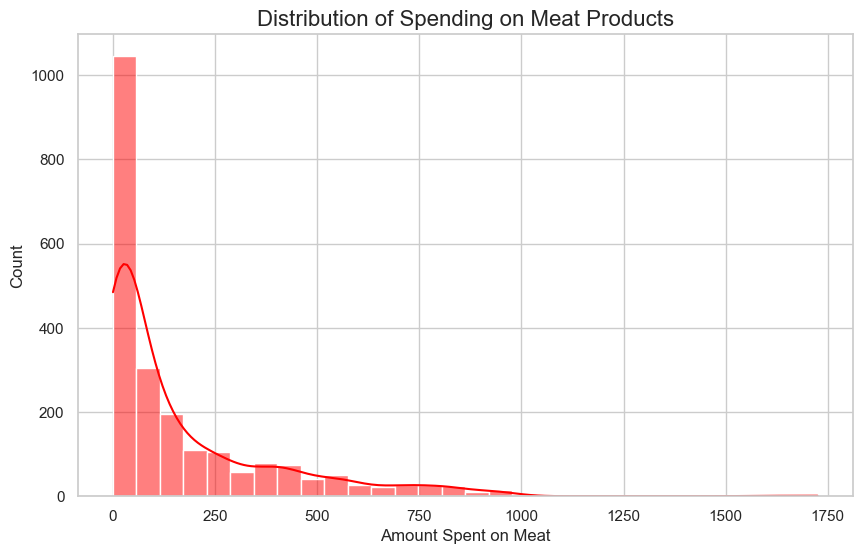

In [18]:
# Plot 3: Distribution of Spending on Meat Products
plt.figure(figsize=(10, 6))
sns.histplot(customer_data_clean['MntMeatProducts'], bins=30, kde=True, color='red')
plt.title('Distribution of Spending on Meat Products', fontsize=16)
plt.xlabel('Amount Spent on Meat', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

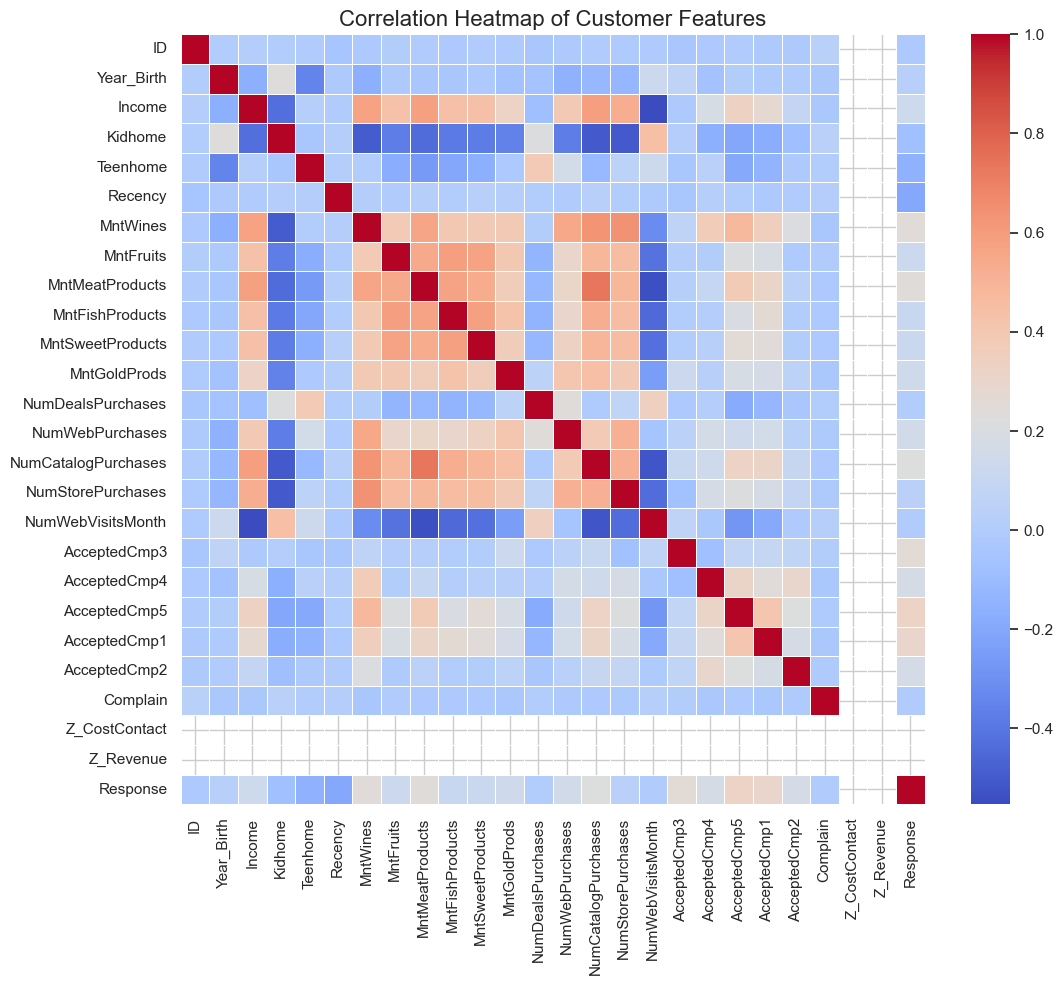

In [19]:
# Plot 4: Correlation Heatmap of Numerical Features
plt.figure(figsize=(12, 10))
numeric_cols = customer_data_clean.select_dtypes(include=[np.number]).columns
corr_matrix = customer_data_clean[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Customer Features', fontsize=16)
plt.show()

### Chapter 2: K-Means Clustering Analysis
## Step 6: Feature Extraction & Scaling

In [20]:
# Select primary numerical features for clustering: Income and Amount Spent on Wines
X = customer_data_clean.loc[:, ['Income', 'MntWines']].values

# Scale the features to give them equal weight in distance calculations
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Feature matrix prepared and scaled successfully.")

Feature matrix prepared and scaled successfully.


## Step 7: Finding Optimal Clusters Using the Elbow Method

In [21]:
print("\nCalculating WCSS for the Elbow Method...")
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
print("WCSS calculation complete.")


Calculating WCSS for the Elbow Method...
WCSS calculation complete.


## Step 8: Plotting the Elbow Method Graph

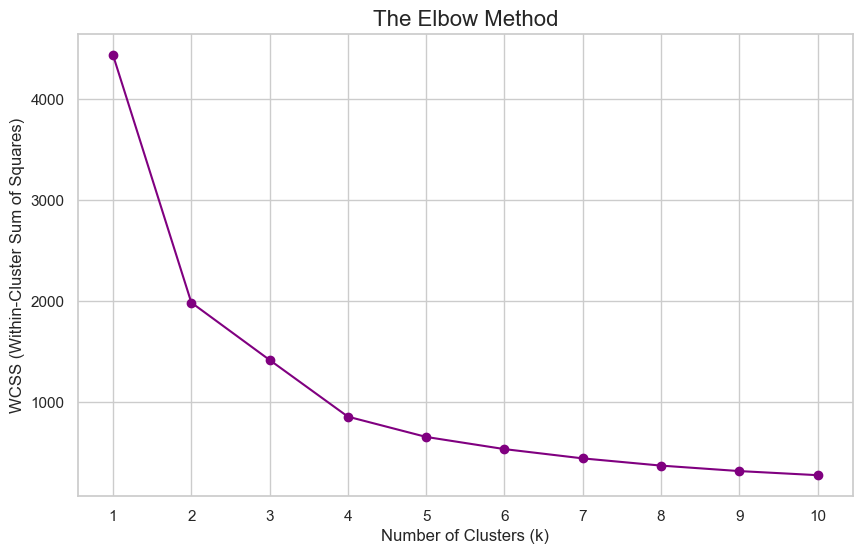

In [22]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='-', color='purple')
plt.title('The Elbow Method', fontsize=16)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('WCSS (Within-Cluster Sum of Squares)', fontsize=12)
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

## Step 9: Validating Clusters Using Silhouette Scores

In [23]:
silhouette_scores = []
for i in range(2, 11):
    km = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10)
    cluster_labels = km.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, cluster_labels)
    silhouette_scores.append(score)
print("Silhouette scores calculated.")

Silhouette scores calculated.


# Step 10: Plotting Silhouette Scores

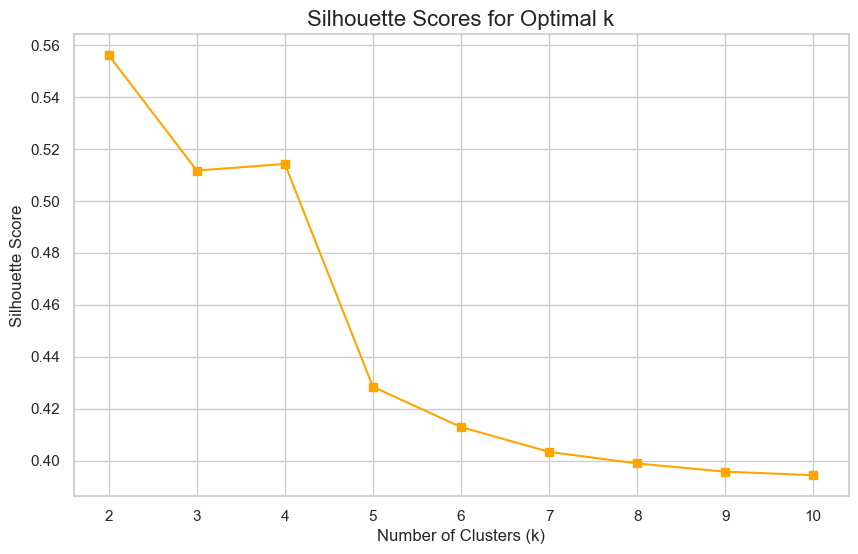

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='s', linestyle='-', color='orange')
plt.title('Silhouette Scores for Optimal k', fontsize=16)
plt.xlabel('Number of Clusters (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.grid(True)
plt.show()

## Step 11: Training K-Means Model with Optimal K

In [25]:
optimal_k = 4
print(f"\nTraining the K-Means model with optimal k = {optimal_k}...")
kmeans_final = KMeans(n_clusters=optimal_k, init='k-means++', random_state=42, n_init=10)


Training the K-Means model with optimal k = 4...


## Step 12: Fit and Predict Clusters

In [26]:
y_kmeans = kmeans_final.fit_predict(X_scaled)
customer_data_clean['Cluster'] = y_kmeans
print("Clustering fit and predict complete.")

Clustering fit and predict complete.


## Step 13: Inspect First 10 Cluster Labels

In [27]:
print("Cluster labels for the first 10 customers:", y_kmeans[:10])

Cluster labels for the first 10 customers: [2 0 2 0 2 2 2 0 0 0]


## Chapter 3: Visualization & Business Insights
## Step 14: Extract Cluster Centroids

In [28]:
centroids = kmeans_final.cluster_centers_
print("Centroids extracted successfully.")

Centroids extracted successfully.


## Step 15: Scatter Plot of Customer Segments

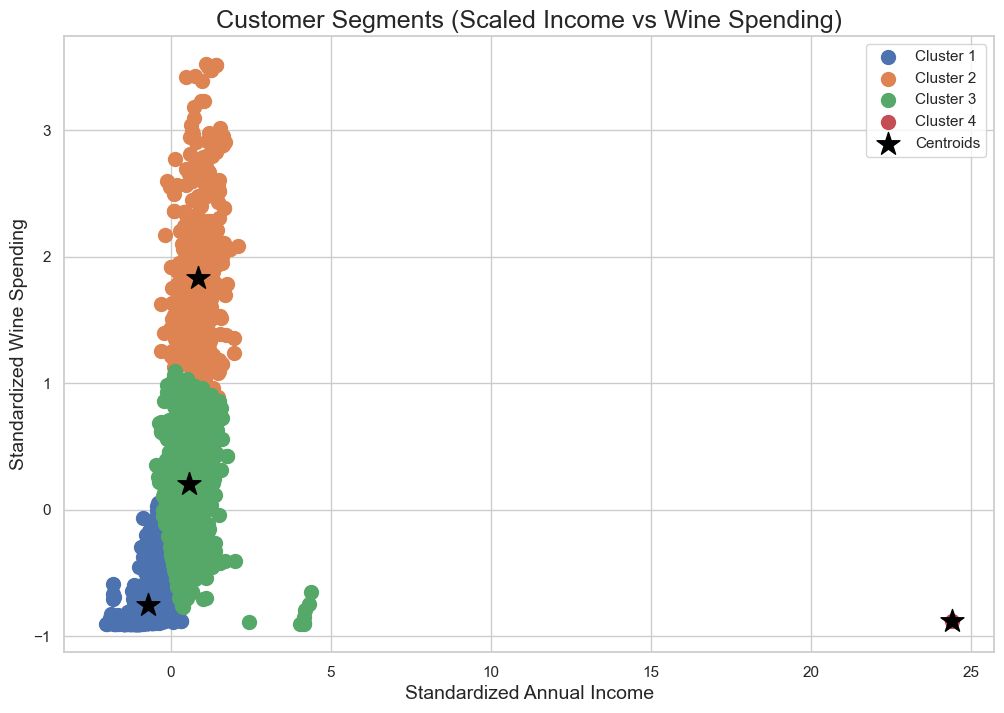

In [29]:
plt.figure(figsize=(12, 8))
for cluster_id in range(optimal_k):
    cluster_data_subset = X_scaled[y_kmeans == cluster_id]
    plt.scatter(cluster_data_subset[:, 0], cluster_data_subset[:, 1], s=100, label=f'Cluster {cluster_id + 1}')

plt.scatter(centroids[:, 0], centroids[:, 1], s=300, c='black', marker='*', label='Centroids')
plt.title('Customer Segments (Scaled Income vs Wine Spending)', fontsize=18)
plt.xlabel('Standardized Annual Income', fontsize=14)
plt.ylabel('Standardized Wine Spending', fontsize=14)
plt.legend()
plt.grid(True)
plt.show()

## Step 16: Groupby Cluster for Profile Analysis

In [30]:
numeric_features = ['Income', 'MntWines', 'MntMeatProducts', 'MntGoldProds', 'NumWebPurchases', 'NumStorePurchases']
cluster_profile = customer_data_clean.groupby('Cluster')[numeric_features].mean()
print("\n--- Cluster Profile Summary (Averages) ---")
print(cluster_profile)


--- Cluster Profile Summary (Averages) ---
                Income    MntWines  MntMeatProducts  MntGoldProds  \
Cluster                                                             
0         34298.939836   51.460346        31.480401     19.838651   
1         74072.587432  924.174863       377.778689     71.316940   
2         66990.344415  374.167553       262.292553     65.890957   
3        666666.000000    9.000000        18.000000     12.000000   

         NumWebPurchases  NumStorePurchases  
Cluster                                      
0               2.431176           3.404740  
1               5.923497           8.674863  
2               5.605053           7.901596  
3               3.000000           3.000000  


## Step 17: Plot Average Spending Bar Chart

<Figure size 1200x600 with 0 Axes>

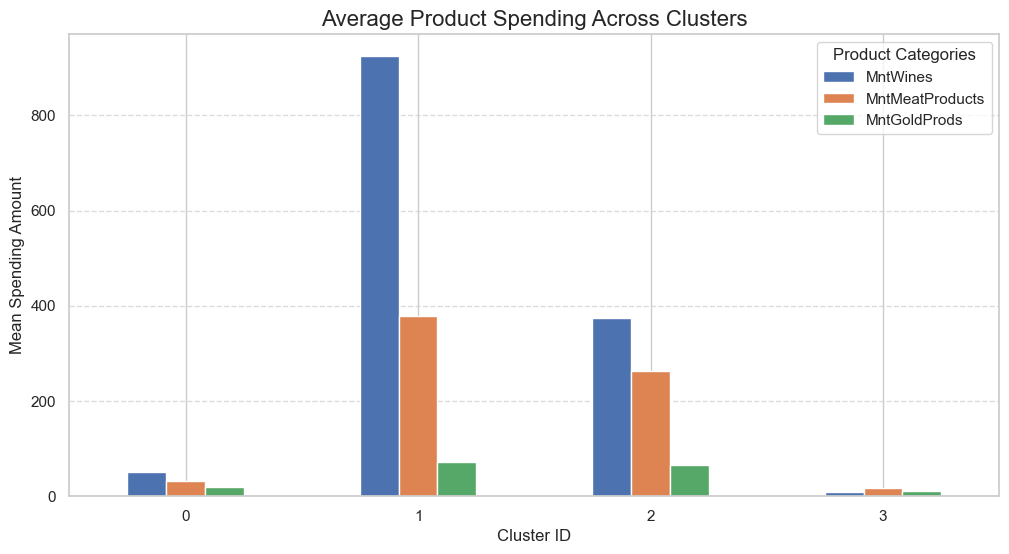

In [31]:
plt.figure(figsize=(12, 6))
cluster_profile[['MntWines', 'MntMeatProducts', 'MntGoldProds']].plot(kind='bar', figsize=(12, 6))
plt.title('Average Product Spending Across Clusters', fontsize=16)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Mean Spending Amount', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Product Categories')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Step 18: Analyze Purchase Channels by Cluster

In [32]:
channel_profile = customer_data_clean.groupby('Cluster')[['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']].mean()
print("\n--- Channel Preferences by Cluster ---")
print(channel_profile)


--- Channel Preferences by Cluster ---
         NumWebPurchases  NumCatalogPurchases  NumStorePurchases
Cluster                                                         
0               2.431176             0.681860           3.404740
1               5.923497             5.568306           8.674863
2               5.605053             4.164894           7.901596
3               3.000000             1.000000           3.000000


## Step 19: Plot Purchase Channels

<Figure size 1000x600 with 0 Axes>

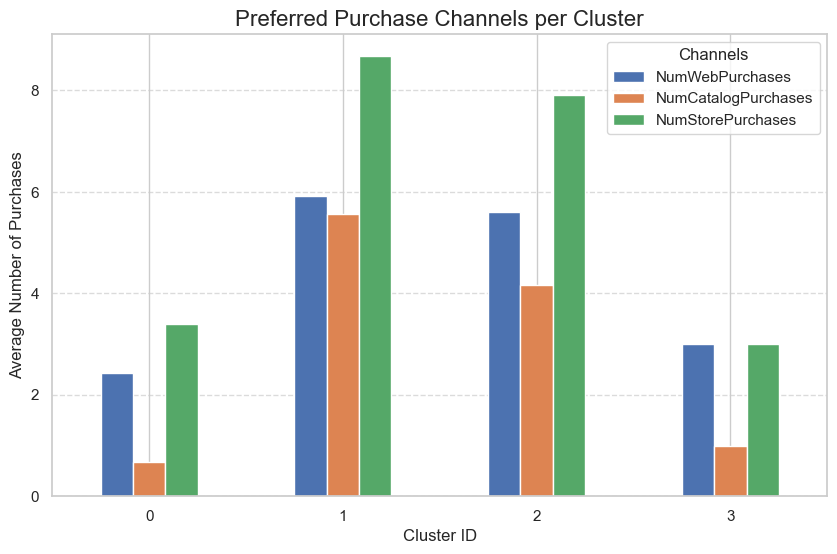

In [33]:
plt.figure(figsize=(10, 6))
channel_profile.plot(kind='bar', figsize=(10, 6))
plt.title('Preferred Purchase Channels per Cluster', fontsize=16)
plt.xlabel('Cluster ID', fontsize=12)
plt.ylabel('Average Number of Purchases', fontsize=12)
plt.xticks(rotation=0)
plt.legend(title='Channels')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Step 20: Campaign Response Analysis

In [34]:
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
campaign_profile = customer_data_clean.groupby('Cluster')[campaign_cols].mean()
print("\n--- Campaign Acceptance Rate by Cluster ---")
print(campaign_profile)


--- Campaign Acceptance Rate by Cluster ---
         AcceptedCmp1  AcceptedCmp2  AcceptedCmp3  AcceptedCmp4  AcceptedCmp5  \
Cluster                                                                         
0            0.000912      0.001823      0.074749      0.012762      0.000000   
1            0.245902      0.060109      0.117486      0.254098      0.338798   
2            0.067819      0.007979      0.050532      0.075798      0.050532   
3            0.000000      0.000000      0.000000      0.000000      0.000000   

         Response  
Cluster            
0        0.103008  
1        0.346995  
2        0.123670  
3        0.000000  


## Step 21: Export Clustered Dataset to CSV

In [38]:
output_checkpoint2 = 'segmented_customers_output.csv'
customer_data_clean.to_csv(output_checkpoint2, index=False)
print(f"Clustered dataset successfully exported to {output_checkpoint2}")

Clustered dataset successfully exported to segmented_customers_output.csv


## Step 22: Summary Statistics Printout

In [39]:
print("\n--- Final Cluster Size Breakdown ---")
print(customer_data_clean['Cluster'].value_counts())


--- Final Cluster Size Breakdown ---
Cluster
0    1097
2     752
1     366
3       1
Name: count, dtype: int64


## Step 23: End of Project Confirmation

In [40]:
print("\nClustering, evaluation, and business insight pipeline complete!")


Clustering, evaluation, and business insight pipeline complete!
